# Basics 3: effects and differential expression

The third of three notebooks that together run or name every public function:

1. [Reading and preparing data](basics_1_data.ipynb)
2. [QC, normalisation and embedding](basics_2_qc_embedding.ipynb)
3. **Effects and differential expression** (this notebook): pseudo-bulk profiles and effects, the Wilcoxon test, the t-test, the negative binomial GLM and its offset form, fold-change shrinkage, result tables and plots.

It runs on its own, on the bundled `data/Adamson_subset.h5ad` (1,716 cells, 11,630 genes, two targets and a control), in under a minute. The table at the end lists the functions of this area, with links to the tutorials that run the heavier methods on real screens.

In [1]:
import os

# Progress bars off, so the saved notebook keeps only crispyx's summary lines; tqdm
# reads this when first imported, so it is set before anything imports tqdm.
os.environ.setdefault('TQDM_DISABLE', '1')

import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import h5py

# Paths stay relative to this notebook's directory so that the paths crispyx
# echoes in its output are the same on every machine.
ROOT = Path('../..')
sys.path.insert(0, str(ROOT / 'src'))
DATA_PATH = ROOT / 'data' / 'Adamson_subset.h5ad'
OUTPUT_DIR = Path('tutorial_outputs') / 'basics_effects'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', message='IProgress not found')

import crispyx as cx
print(f'crispyx {cx.__version__}')

crispyx 0.2.10


## 1. The two input files

Count models read raw counts; rank and mean tests read log-normalised values. Both files come from the previous notebook's steps, repeated here in two calls so that this notebook runs alone.

The bundled dataset has no batch. To show the batch-aware functions, the cell adds a **simulated** `batch` column that splits the cells at random in two, so no batch effect exists and the batch-aware results should agree with the pooled ones.

In [2]:
counts = cx.pp.qc_summary(
    DATA_PATH, perturbation_column='perturbation', control_label='control',
    min_genes=1000, min_cells_per_perturbation=50, min_cells_per_gene=100,
    output_path=OUTPUT_DIR / 'counts.h5ad', verbose=False,
)
counts_path = counts.path

obs = cx.load_obs(counts_path)
obs['batch'] = pd.Categorical(np.random.default_rng(0).choice(['b1', 'b2'], len(obs)))
cx.write_obs(counts_path, obs)

log1p_path = cx.pp.normalize_total_log1p(counts_path, OUTPUT_DIR / 'log1p.h5ad', verbose=False).path
pd.crosstab(obs['perturbation'], obs['batch'])

batch,b1,b2
perturbation,,
AARS,248,218
AMIGO3,357,392
control,229,271


## 2. Pseudo-bulk

`cx.pb` does two different jobs:

| Function | Returns | Notes |
|---|---|---|
| `cx.pb.aggregate` | one **profile** per group of `groupby` (no reference involved) | `method='sum'` for count models, `'mean_log1p'` for log-scale contrasts; `obs` keeps `n_cells` and every column constant within a group |
| `cx.pb.normalized_effects` | one **effect** per perturbation against the control, library-size normalised, from the cells in one pass | `batch_column=` computes the effect within each batch and combines them |
| `cx.pb.effects` | the same contrast per perturbation and batch, on the scale its input carries | reads the cells, or a saved `cx.pb.aggregate` file, so profiles are reused without another pass over the matrix |

Because `cx.pb.effects` does not normalise, its profiles are made here from depth-normalised values (`log1p=False` leaves the log to `method='mean_log1p'`); on raw counts it warns that depth would confound the effect. `cx.pb.normalized_effects` normalises on its own and reads the counts.

In [3]:
normalised_path = cx.pp.normalize_total_log1p(counts_path, OUTPUT_DIR / 'normalised.h5ad', log1p=False, verbose=False).path
profiles = cx.pb.aggregate(
    normalised_path, groupby=['perturbation', 'batch'], method='mean_log1p',
    output_path=OUTPUT_DIR / 'profiles.h5ad', verbose=False,
)
profiles.obs.load()[['perturbation', 'batch', 'n_cells']]

,perturbation,batch,n_cells
pseudobulk_id,,,
control|b2,control,b2,271
AMIGO3|b2,AMIGO3,b2,392
control|b1,control,b1,229
AARS|b2,AARS,b2,218
AARS|b1,AARS,b1,248
AMIGO3|b1,AMIGO3,b1,357


In [4]:
# from the saved profiles: one effect per perturbation and batch
by_batch = cx.pb.effects(
    profiles.path, groupby='perturbation', reference='control', batch_column='batch',
    output_path=OUTPUT_DIR / 'effects_by_batch.h5ad', verbose=False,
)
# from the cells: one normalised effect per perturbation, combined over batches
effects = cx.pb.normalized_effects(
    counts_path, groupby='perturbation', reference='control', batch_column='batch', method='mean_log1p',
    output_path=OUTPUT_DIR / 'effects.h5ad', verbose=False,
)
print('per batch:', by_batch.shape, '| combined:', effects.shape, list(effects.obs.load().index))
by_batch.obs.load()[['perturbation', 'batch', 'n_cells_target', 'n_cells_reference']]

per batch: (4, 9238) | combined: (2, 9238) ['AMIGO3', 'AARS']


,perturbation,batch,n_cells_target,n_cells_reference
effect_id,,,,
effect_00000000,AMIGO3,b2,392,271
effect_00000001,AARS,b2,218,271
effect_00000002,AARS,b1,248,229
effect_00000003,AMIGO3,b1,357,229


## 3. Differential expression

`cx.tl.rank_genes_groups` mirrors `scanpy.tl.rank_genes_groups` and tests every perturbation against the control. `groupby` and `reference` are Scanpy's names for `perturbation_column` and `control_label`; leave `reference` out and a control with a usual name (`control`, `NTC`, ...) is found on its own.

| `method` | Reads | Model |
|---|---|---|
| `'wilcoxon'` | log-normalised values | rank-sum test, streamed gene by gene |
| `'t-test'` | log-normalised values | Welch's t-test from streamed moments |
| `'nb_glm'` | raw counts | negative binomial GLM per gene, with optional `covariates` |

`cx.tl.estimate_disk_usage` reports what a test will write before it runs; on a genome-wide screen that is worth a look first.

In [5]:
for location, estimate in cx.tl.estimate_disk_usage(
        'wilcoxon_test', log1p_path, perturbation_column='perturbation', control_label='control').items():
    print(f'{location}: {estimate.required_bytes / 1e6:.0f} MB needed')

wilcoxon = cx.tl.rank_genes_groups(log1p_path, groupby='perturbation', reference='control', method='wilcoxon',
                                   output_path=OUTPUT_DIR / 'wilcoxon.h5ad', verbose=False)
t_test = cx.tl.rank_genes_groups(log1p_path, groupby='perturbation', reference='control', method='t-test',
                                 output_path=OUTPUT_DIR / 't_test.h5ad', verbose=False)
nb_glm = cx.tl.rank_genes_groups(counts_path, groupby='perturbation', reference='control', method='nb_glm',
                                 output_path=OUTPUT_DIR / 'nb_glm.h5ad', verbose=False)
print('result files:', sorted(Path(result.path).name for result in (wilcoxon, t_test, nb_glm)))

output: 2 MB needed
result files: ['nb_glm.h5ad', 't_test.h5ad', 'wilcoxon.h5ad']


Each result is a file: one row per perturbation, one column per gene, the fold change in `X` and the statistics in layers. `cx.pl.rank_genes_groups_df` reads one perturbation's genes as a table, as `scanpy.get.rank_genes_groups_df` does.

In [6]:
cx.pl.rank_genes_groups_df(nb_glm, group='AARS', n_genes=5)

,names,scores,logfoldchanges,pvals,pvals_adj,pts,pts_rest,group
0,FTH1,29.411153,0.928488,3.954638e-190,3.653295e-186,1.000000,1.000,AARS
1,TPT1,25.233318,0.805912,1.726732e-140,7.975776e-137,0.997854,1.000,AARS
2,PTMA,-24.598165,-0.879377,1.321622e-133,4.069714e-130,0.995708,1.000,AARS
3,PHGDH,23.687018,2.736222,4.906885e-124,1.133245e-120,0.836910,0.314,AARS
4,PHB,-22.420993,-1.023557,2.456455e-111,4.538547e-108,0.927039,0.994,AARS


### Batches as strata: the offset test

With batches, the NB-GLM takes them as `covariates=['batch']`. On screens with hundreds of strata and few cells per perturbation that joint fit is slow, and `cx.tl.nb_offset_test` is its fast form: the controls' mean per stratum is fixed from one pass, and one coefficient per perturbation and gene is fitted on the perturbation's own cells. Here the two batches are random halves, so its fold changes should match the NB-GLM's without covariates.

In [7]:
offset = cx.tl.nb_offset_test(counts_path, groupby='perturbation', reference='control', strata='batch',
                              output_path=OUTPUT_DIR / 'nb_offset.h5ad', verbose=False)

def fold_changes(path):
    with h5py.File(path, 'r') as h5:
        return pd.DataFrame(h5['X'][:], index=h5['obs'][h5['obs'].attrs['_index']][:].astype(str))

glm_lfc, offset_lfc = fold_changes(nb_glm.path), fold_changes(offset.path).reindex(fold_changes(nb_glm.path).index)
tested = np.isfinite(glm_lfc.to_numpy()) & np.isfinite(offset_lfc.to_numpy())
print(f'genes x perturbations tested by both: {tested.sum():,}; correlation of their log2 fold changes: '
      f'{np.corrcoef(glm_lfc.to_numpy()[tested], offset_lfc.to_numpy()[tested])[0, 1]:.4f}')

genes x perturbations tested by both: 18,476; correlation of their log2 fold changes: 0.9986


`cx.tl.nb_offset_test` and the functions behind `rank_genes_groups` (`cx.wilcoxon_test`, `cx.t_test`, `cx.nb_glm_test`) return a `cx.RankGenesGroupsResult`: the result file with `groups`, `genes`, `logfoldchanges`, `pvalues` and the other statistics as arrays read on demand. See [NB-GLM](../nb_glm.rst) for the model, its size factors and when the offset form applies.

## 4. Shrinking fold changes

A fold change estimated from few counts is noisy. `cx.tl.shrink_lfc` applies apeGLM shrinkage to a saved NB-GLM result: uncertain estimates move toward zero, well-supported ones stay. `cx.tl.shrink_lfc_arrays` is the same computation on arrays of fold changes and standard errors (natural log), for estimates that did not come from a crispyx result file; it returns a `cx.ShrunkLFC`.

In [8]:
shrunk = cx.tl.shrink_lfc(nb_glm.path, prior_scale_mode='global', verbose=False)

with h5py.File(nb_glm.path, 'r') as h5:
    lfc, se = h5['layers/logfoldchange_raw_ln'][:], h5['layers/standard_error_ln'][:]
from_arrays = cx.tl.shrink_lfc_arrays(lfc, se)
print(f'{type(from_arrays).__name__}: prior scale {from_arrays.prior_scale:.3f}; '
      f'mean |ln fold change| {np.nanmean(np.abs(lfc)):.3f} -> {np.nanmean(np.abs(from_arrays.lfc)):.3f}')
print('shrunk result file:', Path(shrunk.result_path).name)

ShrunkLFC: prior scale 0.213; mean |ln fold change| 0.189 -> 0.141
shrunk result file: nb_glm_shrunk.h5ad


## 5. Plots

The `cx.pl` functions read a result file and draw with Scanpy's conventions. `cx.pl.volcano` and `cx.pl.top_genes_bar` take the table from `rank_genes_groups_df`; `cx.pl.ma` also reads the counts for the mean expression.

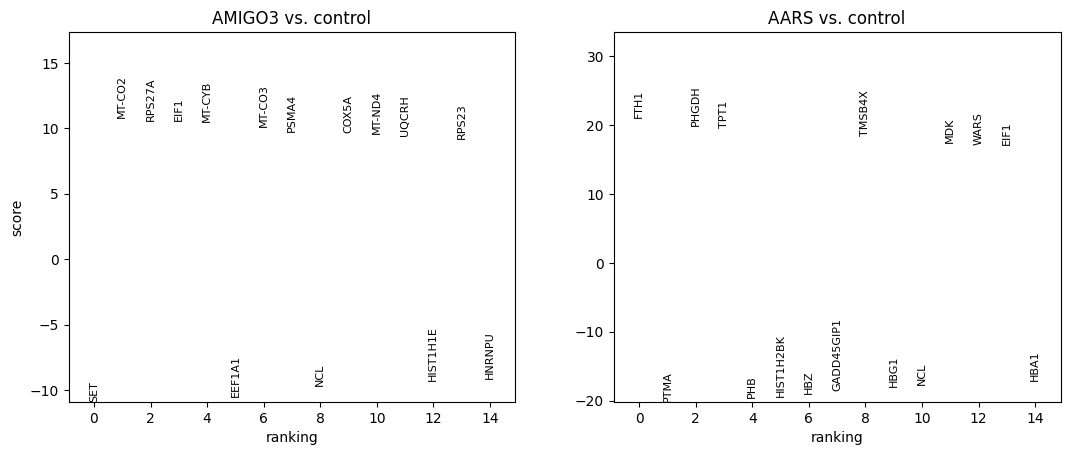

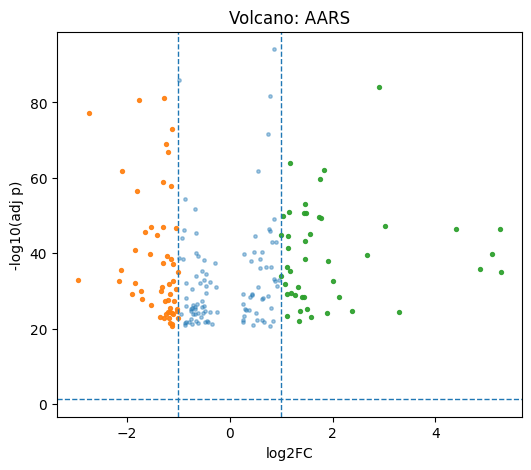

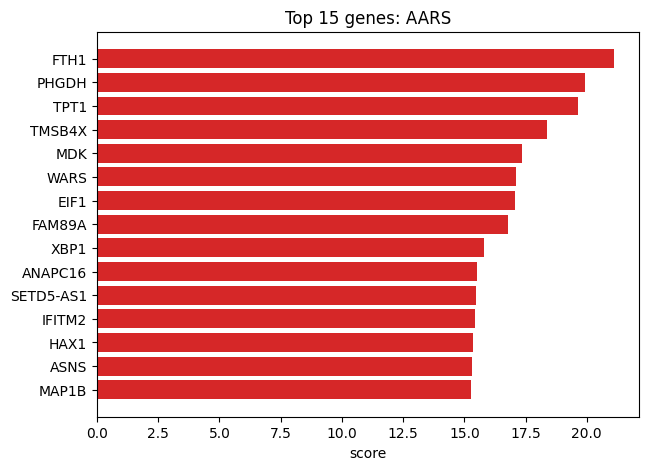

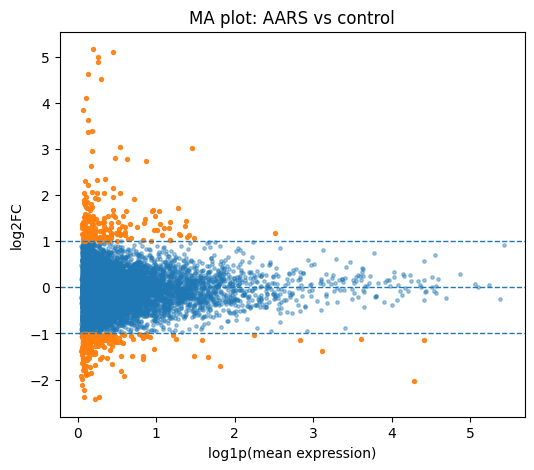

In [9]:
cx.pl.rank_genes_groups(wilcoxon, n_genes=15, sharey=False)

table = cx.pl.rank_genes_groups_df(wilcoxon, group='AARS', n_genes=200)
cx.pl.volcano(de_df=table, group='AARS')
cx.pl.top_genes_bar(de_df=table, group='AARS', topn=15)
_ = cx.pl.ma(data=counts_path, de_result=nb_glm, group='AARS', reference='control',
             perturbation_column='perturbation', mean_mode='raw')

For any other Scanpy plot, `cx.pl.materialize_rank_genes_groups` builds a small in-memory AnnData whose `uns['rank_genes_groups']` is laid out as Scanpy writes it.

In [10]:
for_scanpy = cx.pl.materialize_rank_genes_groups(wilcoxon, n_genes=5)
pd.DataFrame(for_scanpy.uns['rank_genes_groups']['names'])

,AMIGO3,AARS
0,SET,FTH1
1,MT-CO2,PTMA
2,RPS27A,PHGDH
3,EIF1,TPT1
4,MT-CYB,PHB


## 6. Do the tests agree?

`cx.tl.compute_overlap` compares named sets pairwise and returns a `cx.OverlapResult` (counts, Jaccard indices, set sizes); `cx.pl.overlap_heatmap` draws it. Here the sets are the genes each test calls for one target at an adjusted p-value below 0.05.

{'Wilcoxon': 4360, 't-test': 3708, 'NB-GLM': 3480, 'NB offset': 4583}


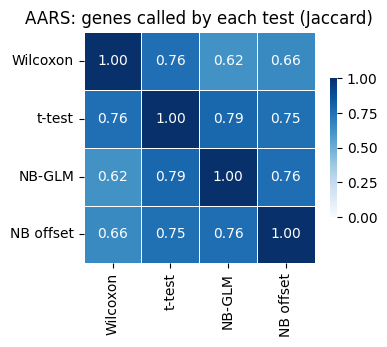

In [11]:
def hits(result, group='AARS'):
    table = cx.pl.rank_genes_groups_df(result, group=group)
    return set(table.loc[table['pvals_adj'] < 0.05, 'names'])

overlap = cx.tl.compute_overlap({'Wilcoxon': hits(wilcoxon), 't-test': hits(t_test),
                                 'NB-GLM': hits(nb_glm), 'NB offset': hits(offset.path)})
print(overlap.set_sizes.to_dict())
_ = cx.pl.overlap_heatmap(overlap, metric='jaccard', title='AARS: genes called by each test (Jaccard)')

## 7. Time and memory of a step

`cx.Profiler` measures named sections of code: wall time, and memory by `tracemalloc` or by the process's resident size. `cx.TimingProfiler` and `cx.MemoryProfiler` are the same with one of the two switched on. The tutorials on real screens use it to report each step's cost.

In [12]:
with cx.Profiler(timing=True, memory=True, memory_method='rss') as profiler:
    profiler.start('t-test')
    cx.tl.rank_genes_groups(log1p_path, groupby='perturbation', reference='control', method='t-test',
                            output_path=OUTPUT_DIR / 't_test_profiled.h5ad', verbose=False)
    profiler.stop('t-test')
print(profiler.get_report())

Profiling Report

Total time: 0.05s

Section Breakdown:
--------------------------------------------------
  t-test                            0.05s (100.0%) █████████████████████████████████████████████████

Memory Snapshots:
--------------------------------------------------
  end                       t=   0.05s  current=  1765.1MB

Peak memory: 1765.1MB


## Functions in this notebook, and beyond it

| Function | What it does | Where |
|---|---|---|
| `cx.pb.aggregate` | pseudo-bulk profile per group | section 2 |
| `cx.pb.effects`, `cx.pb.normalized_effects` | perturbation-minus-control effects from profiles or cells | 2 |
| `cx.tl.rank_genes_groups` (`cx.wilcoxon_test`, `cx.t_test`, `cx.nb_glm_test`) | each perturbation against the control | 3 |
| `cx.tl.nb_offset_test` | NB test with the controls as a fixed per-stratum baseline | 3 |
| `cx.RankGenesGroupsResult` | a result file read as arrays | 3 |
| `cx.tl.shrink_lfc`, `cx.tl.shrink_lfc_arrays`, `cx.ShrunkLFC` | apeGLM shrinkage of fold changes | 4 |
| `cx.pl.rank_genes_groups`, `cx.pl.rank_genes_groups_df`, `cx.pl.volcano`, `cx.pl.top_genes_bar`, `cx.pl.ma` | result tables and plots | 3, 5 |
| `cx.pl.materialize_rank_genes_groups` | a result in Scanpy's `uns` layout | 5 |
| `cx.tl.compute_overlap`, `cx.OverlapResult`, `cx.pl.overlap_heatmap` | overlap of named sets | 6 |
| `cx.tl.estimate_disk_usage` | disk a function will need | 3 |
| `cx.Profiler`, `cx.TimingProfiler`, `cx.MemoryProfiler` | time and memory of code sections | 7 |

Not run here, because they need what a small three-label dataset cannot show:

| Function | What it does | Tutorial |
|---|---|---|
| `cx.tl.residual_effects` | covariate-adjusted effects: each gene fitted to covariates on the control cells, a perturbation's effect the mean residual of its cells | [targeted screen](residual_effects_targeted_feng.ipynb), [genome-wide screen](residual_effects_genomewide_zhu.ipynb) |
| Wilcoxon test with `batch_column=` | rank test stratified by batch, with batch-corrected effects | [batch-corrected effects and Wilcoxon tests](stratified_wilcoxon_tutorial.ipynb) |
| `cx.tl.batch_process`, `cx.BatchReducer`, `cx.BatchStatistic` | your own streamed gene-wise statistic, computed within batches | [custom batch statistics](batch_statistics_tutorial.ipynb) |
| NB-GLM size factors (`size_factor_method=`) | how the choice changes the fit | [size-factor comparison](size_factor_comparison.ipynb) |

More on each step: [Pseudo-bulk](../pseudobulk.rst), [Differential expression](../differential_expression.rst), [NB-GLM](../nb_glm.rst), [Covariate adjustment](../covariate_adjustment.rst).